<a href="https://colab.research.google.com/github/ascr0wn/google_colab_notebooks/blob/main/01_ffnn_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer, load_iris
import os
from google.colab import drive # to save datasets in drive
import shutil # to copy to drive
import seaborn as sns

drive.mount("/content/drive") #mount so to get dataset at the start of runtime is possible from drive


Mounted at /content/drive


In [ ]:
### Method 1 - Use library in-built dataset ###
bunch = load_breast_cancer() # returns sklearn's bunch object
print(type(bunch), type(bunch.data))
print(bunch.keys())
print(bunch.data.shape, bunch.target.shape)
print(bunch.target_names) #bunch is dictionary like because it can be accessed like this also: bunch["target_names"] #bunch.something (like data, target, frame, ...) returns a numpy ndarray (except DESCR which is python str)
print(bunch.DESCR) #Description about dataset

<class 'sklearn.utils._bunch.Bunch'> <class 'numpy.ndarray'>
dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])
(569, 30) (569,)
['malignant' 'benign']
.. _breast_cancer_dataset:

Breast cancer wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the 

In [ ]:
# ### Method 2 Import an online dataset ###
# url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
# col_names = ["pregnancies", "glucose", "blood_pressure", "skin_thickness", "insulin", "bmi", "pedigree", "age", "outcome"]
# df = pd.read_csv(url, header=None, names=col_names) #since this dataset doesn't have 1st row as column names then we have to specify that so it doesn't use 1st row as column names. and give it column names!
# print(f"shape of dataset: {df.shape}")
# print(f"top 5 rows of datasest: {df.head()}")

In [ ]:
# os.makedirs("data/raw", exist_ok=True) #if already exists don't throw an error!
# df.to_csv("data/raw/pima.csv", index=False)
# raw = pd.read_csv("data/raw/pima.csv")
# df = raw.copy()
# #no need to actually do this since we already assigned df before! basically now we have two dataset 1. raw: stays in ram, when you want to refer original, df: stays in ram, do changes in this.
# #changes in either do not reflect in locally saved pima.csv (if df = raw then changing one would change another too)
# print(os.listdir("data/raw"))

In [ ]:
# from google.colab import drive
# import shutil

# drive.mount("/content/drive") #
# os.makedirs("/content/drive/MyDrive/deep-learning/data", exist_ok=True)
# shutil.copy("data/raw/pima.csv", "/content/drive/MyDrive/deep-learning/data/pima.csv")

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

path  = "/content/drive/MyDrive/deep-learning/data/pima.csv"

col_names = ["pregnancies", "glucose", "blood_pressure", "skin_thickness", "insulin", "bmi", "pedigree", "age", "outcome"]
raw = pd.read_csv(path, header=None, names=col_names)
df = raw.copy()

print("Dataset shape:", df.shape)
print(df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset shape: (769, 9)
   pregnancies  glucose  blood_pressure  skin_thickness  insulin   bmi  \
0  pregnancies  glucose  blood_pressure  skin_thickness  insulin   bmi   
1            6      148              72              35        0  33.6   
2            1       85              66              29        0  26.6   
3            8      183              64               0        0  23.3   
4            1       89              66              23       94  28.1   

   pedigree  age  outcome  
0  pedigree  age  outcome  
1     0.627   50        1  
2     0.351   31        0  
3     0.672   32        1  
4     0.167   21        0  


In [ ]:
from torchvision import datasets
train_set = datasets.FashionMNIST("data", train=True, download=True) #download if not present locally already the training split of the data at location /data/
print(len(train_set)) #60000 tuples in which 1st element is image and 2nd is it's label.
print(type(train_set)) #image and label are python (PIL) image and integer
img, label = train_set[0] #1st img and label of 60000 rows
print(f"image type: {type(img)}---, img: {img}---, label type: {type(label)}---, label: {label}")
os.listdir("data")

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 165kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.10MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 23.9MB/s]

60000
<class 'torchvision.datasets.mnist.FashionMNIST'>
image type: <class 'PIL.Image.Image'>---, img: <PIL.Image.Image image mode=L size=28x28 at 0x7C272AAB8050>---, label type: <class 'int'>---, label: 9


['FashionMNIST']

In [ ]:
#Hugging Face Datasets
!pip install -q datasets # -q is quiet mode, reduces messages while installing

from datasets import load_dataset

ds = load_dataset("stanfordnlp/imdb") #returns datasetdict with 25k rows for each train and test split. dataset -> train , test -> text , label
#ds is datasetdict, it has train/test which is of type dataset, it has rows that are (each) dictionaries, they have two keys (int) label and (str) text
#unsupervised section/split doesn't have label, just text

print(ds)

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


In [ ]:
print(ds["train"][0]["label"]) #1st review in training split's label
print(ds["train"][0]["text"][:101]) #1st review in training split's text (only first 100 characters!)

0
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it wh


In [ ]:
# from google.colab import files
# file = files.upload() #upload files from local storage
# pd.read_csv(
#     "file.csv",
#     header=0,       # First row contains column names (default)
#     sep=",",        # Delimiter
#     encoding="utf-8"
# )

pima dataset value counts: outcome
0    500
1    268
Name: count, dtype: int64
<class 'sklearn.utils._bunch.Bunch'>
['setosa' 'versicolor' 'virginica']
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   
5                5.4               3.9                1.7               0.4   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  
5       0  
.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and th

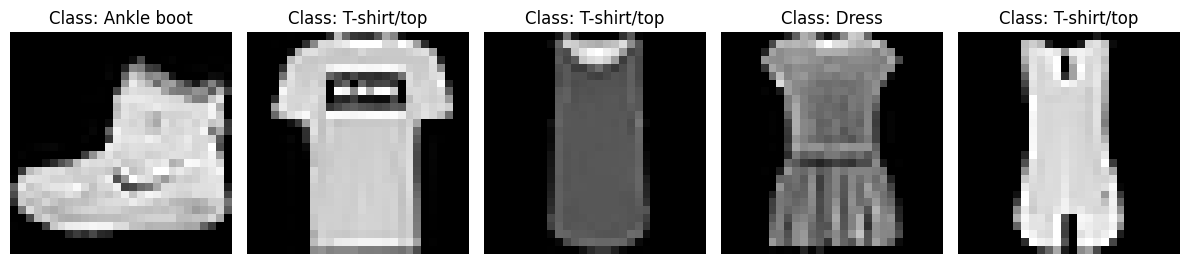

In [ ]:
'''
Quiz
Why does pd.read_csv(url) give wrong column names for the Pima file, and what two arguments fix it?
What’s the difference between df = raw and df = raw.copy()?
You trained for an hour in Colab and saved model.pt to the notebook’s local folder, and the session disconnected. What happens to it, and how do you avoid that?
What does download=True do in datasets.FashionMNIST(...), and why is it harmless to run again?
Name three things you’d check right after loading a new dataset.
Exercises
Load the Pima data as above, then print df["outcome"].value_counts() and df.describe(). Predict first: is it balanced? Look at the minimum values of glucose, blood_pressure and bmi. Do they make sense for living patients?
Load the iris dataset with sklearn.datasets.load_iris(as_frame=True), print .DESCR, and write down in a markdown cell what one row represents and how many classes there are.
Download FashionMNIST as above and display the first 5 images side by side with their class numbers as titles, using plt.subplots(1, 5) and imshow(img, cmap="gray").

Quiz Answers:
1. because the dataset doesn't contain header so when the program reads csv and takes the first row as header it just gets first row values. making an array of column names and sending it to the function with argument
names solves that (it is manual).
2. raw and raw.copy() both live on RAM but raw represents the original dataset if ever you want to refer that and they are separate from each other, so the idea is that you make changes in raw.copy() dataset and refer
raw whenever you want!
3. the storage in google colab is temporary and it is gone once session disconnected, to aviod we can save the modified dataset to google drive and next time instead of getting it from the source, we get it from google drive!
4. downloads the dataset locally, don't if it already exists so it is harmless to run again and again!
5. whether it has a header or not, it's shape, it's train test split, the datastructure/type it is in, how it is structured/formatted, most of it by looking at it's DESCR or README or AI LLM i can ask!
'''
#exercise 1
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
col_names = ["pregnancies", "glucose", "blood_pressure", "skin_thickness", "insulin", "bmi", "pedigree", "age", "outcome"]
pima_ds = pd.read_csv(url, header=None, names=col_names)
print(f"pima dataset value counts: {pima_ds["outcome"].value_counts()}") #not balanced obviously!
pima_ds.describe() #minimum values for glucose, blooc_pressure and insulin are literally 0, it doesn't make sense, is the data noisy/incorrect?

#exercise 2
from sklearn.datasets import load_iris
iris_df = load_iris(as_frame=True) #bunch object as dataframe, bunch has: data(dataframe) (150rows, 4columns), target(series)(150rows, 1columns), frame(dataframe)(150rows, 5columns), target_names(array)(3 classification)
#DESCR, feature_names, file_name, data_module
print(type(iris_df))
print(iris_df.target_names)
print(iris_df.frame[:6])
print(iris_df.DESCR)
#basically this dataset has 5 columns, out of 4 are features and 1 targer, total 3 output classes and 150 rows/examples. the model learns sepal and petal's length and width to determine which type of iris flower it is!

#exercise 3
import matplotlib.pyplot as plt
from torchvision import datasets
train_set = datasets.FashionMNIST(root="data", train=True, download=True) #download if not present locally already the training split of the data at location /data/
fig, axes = plt.subplots(1,5, figsize=(12,3))
classes = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]
for i in range(5):
  img, label = train_set[i]
  axes[i].imshow(img, cmap="gray")
  axes[i].set_title(f"Class: {classes[label]}")
  axes[i].axis("off")
plt.tight_layout()
plt.show()


In [ ]:
### --- Exploring the data (EDA) --- ###

In [ ]:
path  = "/content/drive/MyDrive/deep-learning/data/pima.csv"

col_names = ["pregnancies", "glucose", "blood_pressure", "skin_thickness", "insulin", "bmi", "pedigree", "age", "outcome"]
pima_ds = pd.read_csv(path, header=0, names=col_names) #original dataset do not have a header but our copy in google drive has a header at index 0

print(pima_ds.shape)
pima_ds.info()
pima_ds.head()

print(pima_ds.isna().sum())
print(pima_ds.duplicated().sum())
'''
so isna() returns a boolean dataframe that has equal size to our dataset dataframe and sum() does a column wise(by default, for row wise do axis=1)
sum of true values (that are na) and returns us a series of equal length as number of columns with sum of na values in each column!
for duplicated we get a boolean series, where first occurance of any row is false and second is true, so for every row marked true it has came before, we can tell!
'''
no_zero_cols = ["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]
print(f"number of zeroes in columns that mustn't be zero(abnormal):  {(pima_ds[no_zero_cols] == 0).sum()}")
print(f"percentage of zero values in terms of total values: {(pima_ds[no_zero_cols] == 0).mean().mul(100).round(1)}")
pima_ds.head(10)

(768, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   pregnancies     768 non-null    int64  
 1   glucose         768 non-null    int64  
 2   blood_pressure  768 non-null    int64  
 3   skin_thickness  768 non-null    int64  
 4   insulin         768 non-null    int64  
 5   bmi             768 non-null    float64
 6   pedigree        768 non-null    float64
 7   age             768 non-null    int64  
 8   outcome         768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
pregnancies       0
glucose           0
blood_pressure    0
skin_thickness    0
insulin           0
bmi               0
pedigree          0
age               0
outcome           0
dtype: int64
0
number of zeroes in columns that mustn't be zero(abnormal):  glucose             5
blood_pressure     35
skin_thickness    227
insulin           3

,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,pedigree,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


In [ ]:
pima_ds.describe().T #explains with columns as rows
#look at the max and mean values of some columns and how different they are from each other like max of insulin is 846 and pedigree is 2.42. a model donot train well based on this. we need to scale the values.

,count,mean,std,min,25%,50%,75%,max
pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
blood_pressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
skin_thickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
bmi,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
pedigree,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [ ]:
print(pima_ds.value_counts("outcome")) #dataset not balanced a naive model only predicting one class can have accuracy 65 percent, that's the minimum baseline our model must beat!
print(pima_ds.value_counts("outcome", normalize=True))

outcome
0    500
1    268
Name: count, dtype: int64
outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64


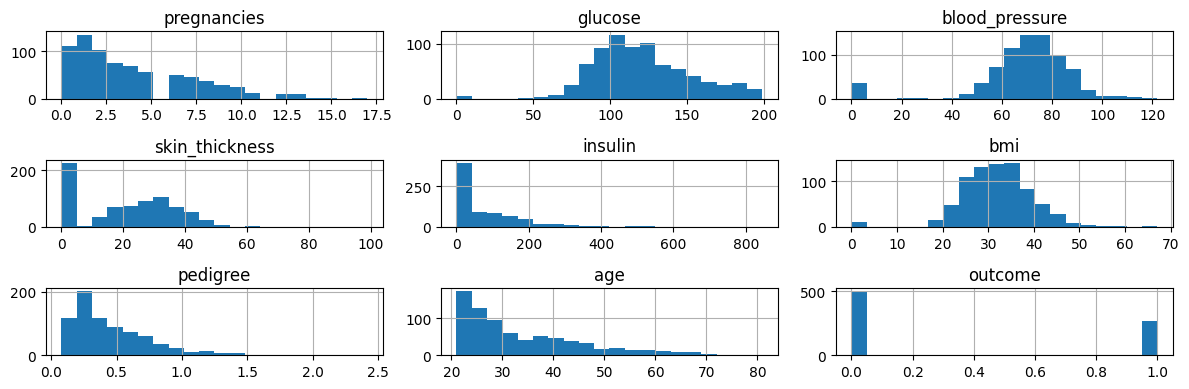

In [ ]:
import matplotlib.pyplot as plt
pima_ds.hist(bins=20, figsize=(12,4))
plt.tight_layout()
plt.show()
#too many zeroes in skin thickness, insulin, and some in blood_pressure (abnormal data).
#whereas pedigree, insulin and age data is skewed, too many yound people but not enough old people are present (could be good or bad based on what we want to do)

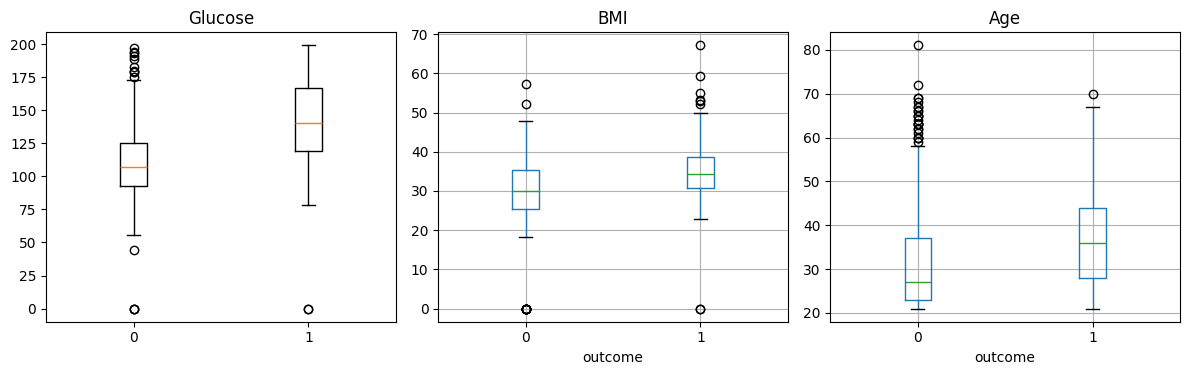

In [ ]:
pima_ds.groupby("outcome").mean().round(2).T
fig, axes = plt.subplots(1,3, figsize=(12,4))
axes[0].boxplot(pima_ds[pima_ds["outcome"] == 0]["glucose"], positions=[0])
axes[0].boxplot(pima_ds[pima_ds["outcome"] == 1]["glucose"], positions=[1])
axes[0].set_title("Glucose")

pima_ds.boxplot(column="bmi", by="outcome", ax=axes[1]) #two ways to do the same thing
axes[1].set_title("BMI")
pima_ds.boxplot(column="age", by="outcome", ax=axes[2])
axes[2].set_title("Age")

plt.suptitle("")
plt.tight_layout()
plt.show()

#lower box is 25th percentile, middle in-box line is 50th percentile and top line of the box represents 75percentile of the values for that outcome. the extreme points (whiskers) are outliers.
#we can see for outcome 1 all glucose, bmi and age are higher than for outcome 0

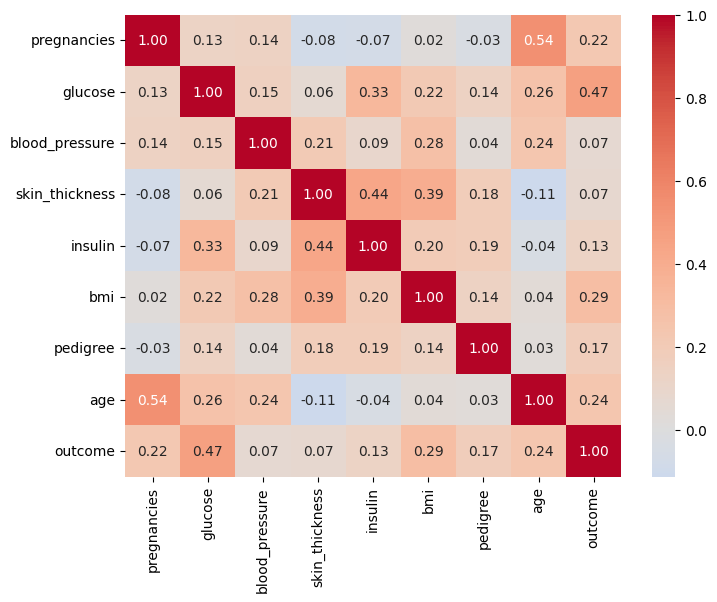

outcome           1.000000
glucose           0.466581
bmi               0.292695
age               0.238356
pregnancies       0.221898
pedigree          0.173844
insulin           0.130548
skin_thickness    0.074752
blood_pressure    0.065068
Name: outcome, dtype: float64


In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(pima_ds.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()
print(pima_ds.corr()["outcome"].sort_values(ascending=False))
#glucose has highest correlation with outcome, age and pregnancies are correlated, same with skin_thickness and insulin. outcome depends on top 3 are: glucose, bmi, age.

In [ ]:
'''
Summary:
1. 768 rows, 8 features, binary target (outcome, 1 = diabetes). No NaN, but see below.
2. Imbalance of about 65% / 35%, so the baseline accuracy is 65.1% and I’ll report precision, recall and F1 too.
3. Hidden missing values (zeros) in glucose, blood_pressure, skin_thickness, insulin, bmi.
4. Very different feature scales, so I need to standardize.
5. insulin, pedigree and age are right-skewed.
6. glucose is the strongest predictor; age and pregnancies overlap.
To-do for 1.3: turn the fake zeros into NaN, decide how to fill them, and scale features.
'''

'\nSummary:\n1. 768 rows, 8 features, binary target (outcome, 1 = diabetes). No NaN, but see below.\n2. Imbalance of about 65% / 35%, so the baseline accuracy is 65.1% and I’ll report precision, recall and F1 too.\n3. Hidden missing values (zeros) in glucose, blood_pressure, skin_thickness, insulin, bmi.\n4. Very different feature scales, so I need to standardize.\n5. insulin, pedigree and age are right-skewed.\n6. glucose is the strongest predictor; age and pregnancies overlap.\nTo-do for 1.3: turn the fake zeros into NaN, decide how to fill them, and scale features.\n'


    sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0   (150, 5)

 target
0    50
1    50
2    50
Name: count, dtype: int64

                    count      mean       std  min  25%   50%  75%  max
sepal length (cm)  150.0  5.843333  0.828066  4.3  5.1  5.80  6.4  7.9
sepal width (cm)   150.0  3.057333  0.435866  2.0  2.8  3.00  3.3  4.4
petal length (cm)  150.0  3.758000  1.765298  1.0  1.6  4.35  5.1  6.9
petal width (cm)   150.0  1.199333  0.762238  0.1  0.3  1.30  1.8  2.5
target             150.0  

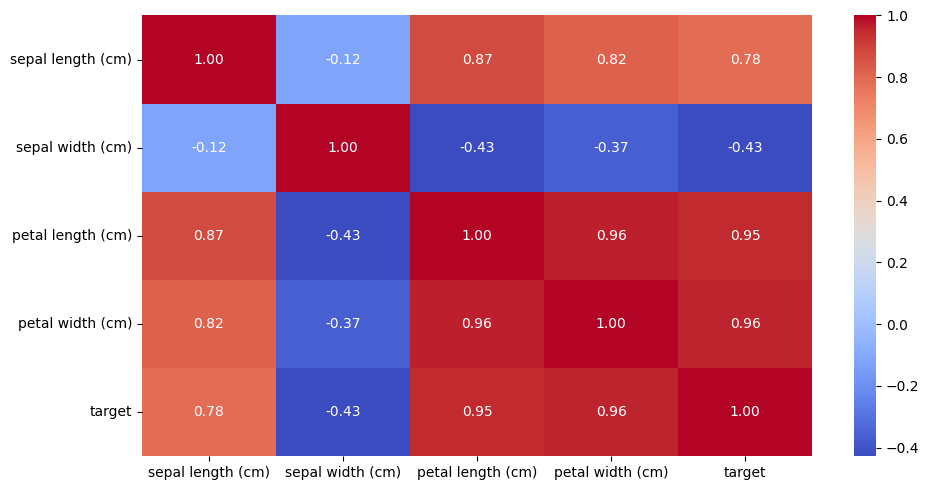

48.95833333333333


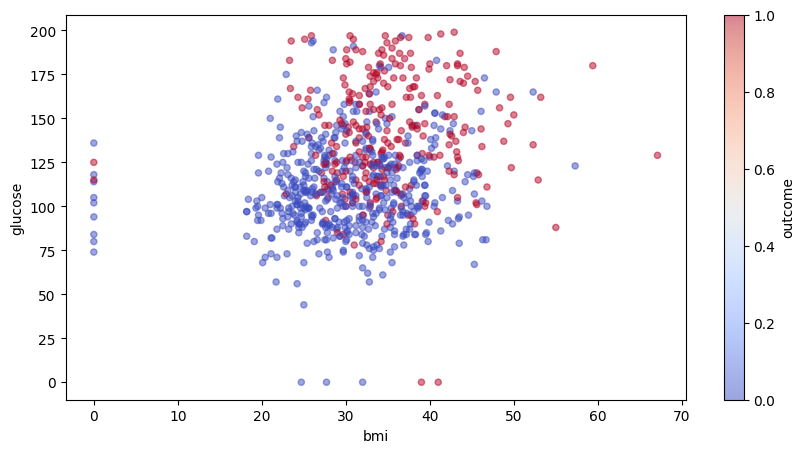

In [ ]:
'''
Quiz
df.isna().sum() is all zeros, yet Pima has missing values. Explain.
Which zeros in Pima are legitimate and which aren’t? How do you decide for a new dataset?
With a 65/35 split, what accuracy does “always predict 0” get, and which metrics would you add besides accuracy?
Why does describe() showing very different scales matter for a neural network?
What does a correlation of 0.47 between glucose and outcome tell you, and what doesn’t it tell you?

Exercises
Run the same EDA on iris (load it with load_iris(as_frame=True) and use iris.frame). Write 5 bullet findings: balance, scales, missing values, which feature separates the classes best (use groupby("target").mean()), and any strong feature-to-feature correlation.
For Pima, count rows with at least one hidden missing value among the five columns: (df[cols_no_zero] == 0).any(axis=1).sum(). Predict first whether it’s under or over a quarter of the data. Would simply deleting those rows be a good idea? What would you lose?
Draw a scatter plot of glucose against bmi, coloured by outcome with alpha=0.5. Describe what you see in one sentence, including what the zeros look like.

Quiz Answers:
1. na values in the dataset has just being replaced by zeroes.
2. pregnancies or age can be 0 for a normal human being, but bmi, glucose, insulin, .. cannot be zero so we can infer that these must be na values replaced by zeroes.
3. a naive model may predict only 0 and still get 65 percent accuracy, but we know that model cannot be trusted. so we need metrics like precision, recall and f1_score to judge outcome wise how many predictions were right
and how many right predictions were made in total (trustworhtyness and completeness of the model).
4. for unscaled columns if 1 is very big while another is very small then the problem is that after calculating the gradients and trying to update weights the learning rate for both are same so either one takes a huge jump
while updating weights or one takes a very small jump. both are not good and optimised way to find optimal weights so we scale the features so finding w's using single learning rate becomes easier and better.
5. correlation simply tells us that as one element changes how it affect the other element. does 1 increasing also increases other and so on. high correralation (close to 1) means that the elements are highly correlated
and changing one will affect the other. it is from -1 to +1: increase one decreases the other (-1) and increases one increases other (+1). but it can only detect linear relationships and completely fail on any complex
non linear relation.
'''
#Exercise 1
iris = load_iris(as_frame=True)
print("\n",iris.frame.head(), iris.frame.shape) #150 rows, 5 columns, based on petal, sepal height and width in a flower predicts its iris flower type out of 3.
print("\n",iris.frame.value_counts("target")) #extremely balanced dataset
print("\n",iris.frame.describe().T) # the data features are not scaled (especially petal width with other 3). also min and max shows proper values that could mean the dataset doesn't use zero as filler for na values.
print("\n", iris.frame.isna().sum()) #no null values hence do not requries us managing that!
print("\n", iris.frame.corr()["target"]) #petal length and petal width are highly, strongly correlated with target but since this is a classification dataset, we have to take it with a pinch of salt!
plt.figure(figsize=(10,5))
sns.heatmap(iris.frame.corr(), annot=True, fmt=".2f", cmap="coolwarm") #we can see that petal length and width are highly correlated, whereas sepal length and width are not very correlated (-0.12)
plt.tight_layout()
plt.show()

#Exercise 2
#well i predict atleast 20 percent of the rows would have zero or na values. let's check!
print(((pima_ds[no_zero_cols] == 0).any(axis=1).sum())/pima_ds.shape[0] * 100) #almost 50 percent rows have atleast one or more zero values. obviously we cannot just delete, it will result in too much data loss,
#instead we can replace these zeroes by some approximations of what could be here instead of removing the row or leaving the zero.

#Exercise 3
pima_ds.plot.scatter(x="bmi", y="glucose", c="outcome", colormap="coolwarm", alpha=0.5, figsize=(10, 5))
plt.show()
#i notice that around bmi > 25to30 and glucose > 100 the red dots starts increasing. the zeroes can be seen in the edges of the map with both blue and red dots, they are just redundant in this graph, no use.
